In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import kagglehub
import os
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr

# One colour per meaning, used in every plot of the notebook.
C_SURVIVED = "#2a78d6"   # blue
C_DIED = "#eb6834"       # orange
C_NEUTRAL = "#2a78d6"    # single-series bars (counts)
C_MISSING = "#8a8986"    # grey for "missing"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

Kaggle API token (read from Colab Secrets or the `.env` file, never written in the notebook)

In [ ]:
# Make the Kaggle token available to kagglehub, without ever writing it in the notebook:
# from Colab Secrets on Colab, otherwise from the project's .env file,
# an environment variable, or ~/.kaggle/access_token.
try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
except ImportError:
    try:
        from dotenv import load_dotenv
        load_dotenv(Path("..") / ".env")   # the notebook lives in notebooks/, .env in the project folder
    except ImportError:
        pass                               # python-dotenv not installed: use the environment variable

Loading data from kaggle

In [ ]:
def load_titanic_train() -> pd.DataFrame:
    """Fetch train.csv from the Kaggle Titanic competition (test.csv is never downloaded)."""
    try:
        path = Path(kagglehub.competition_download("titanic", path="train.csv"))
    except Exception as e:
        raise RuntimeError(
            "Could not download train.csv from Kaggle. Check that your KAGGLE_API_TOKEN is set "
            "and that you accepted the rules at kaggle.com/competitions/titanic.\n"
            f"Original error: {type(e).__name__}: {e}"
        ) from e
    if path.is_dir():
        path = path / "train.csv"
    print(f"Downloaded to {path}")
    return pd.read_csv(path)


df = load_titanic_train()
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")

In [ ]:
df.head(20)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


**EDA**

Duplicates:

In [ ]:
# Checking for duplicates

print(f"Fully identical rows:             {df.duplicated().sum()}")
print(f"Identical apart from PassengerId: {df.drop(columns='PassengerId').duplicated().sum()}")
print(f"PassengerId unique:               {df['PassengerId'].is_unique}")

Fully identical rows:             0
Identical apart from PassengerId: 0
PassengerId unique:               True


Missing Values:

In [ ]:
# Checking for missing values

PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none"}

def count_placeholders(s: pd.Series) -> int:
    """Text values that mean 'missing' but are not real NaN (e.g. 'N/A', 'null', '')."""
    if not (pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s)):
        return 0
    return s.dropna().astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()

column_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "NaN": df.isna().sum(),
    "placeholder_text": [count_placeholders(df[c]) for c in df.columns],
})
column_report["total_missing"] = column_report["NaN"] + column_report["placeholder_text"]
column_report["missing_%"] = (column_report["total_missing"] / len(df) * 100).round(1)
display(column_report)

rows_missing = df.isna().any(axis=1)
print(f"Rows with at least one missing value: {rows_missing.sum()} of {len(df)} ({rows_missing.mean():.1%})")
print(f"Rows with no missing values:          {(~rows_missing).sum()}")

# Which combinations of columns are missing together, and how often.
pattern = df.isna().apply(lambda r: ", ".join(df.columns[r]) or "(nothing missing)", axis=1)
display(pattern.value_counts().rename_axis("missing columns").to_frame("rows"))

,dtype,NaN,placeholder_text,total_missing,missing_%
PassengerId,int64,0,0,0,0.0
Survived,int64,0,0,0,0.0
Pclass,int64,0,0,0,0.0
Name,object,0,0,0,0.0
Sex,object,0,0,0,0.0
Age,float64,177,0,177,19.9
SibSp,int64,0,0,0,0.0
Parch,int64,0,0,0,0.0
Ticket,object,0,0,0,0.0
Fare,float64,0,0,0,0.0


Rows with at least one missing value: 708 of 891 (79.5%)
Rows with no missing values:          183


,rows
missing columns,
Cabin,529
(nothing missing),183
"Age, Cabin",158
Age,19
Embarked,2


Analysing Categorical Columns:

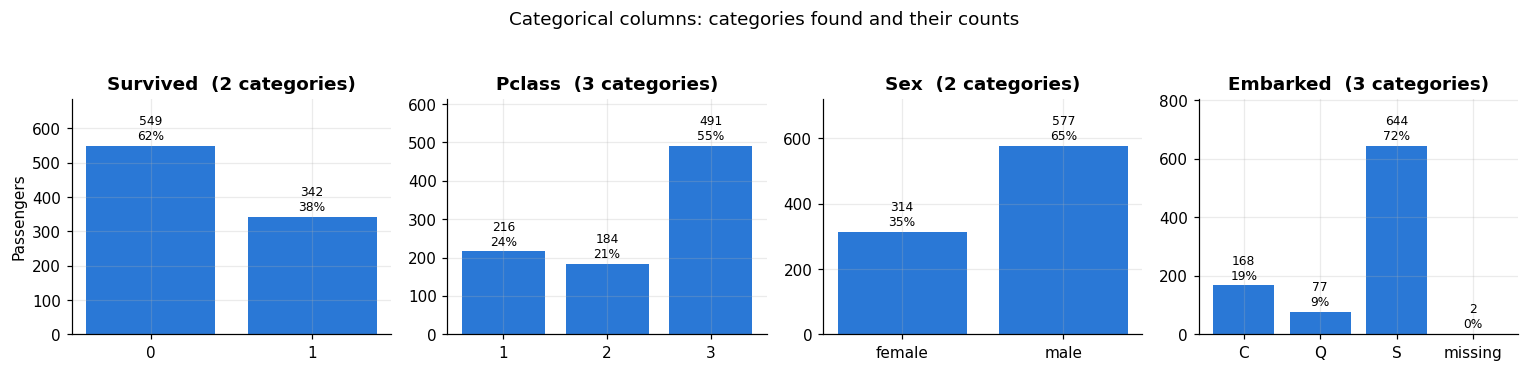

In [ ]:
# Analysing categorical data: every category present in the data, with its count.

CATEGORICAL_COLS = ["Survived", "Pclass", "Sex", "Embarked"]

fig, axes = plt.subplots(1, len(CATEGORICAL_COLS), figsize=(14, 3.2))
for ax, col in zip(axes, CATEGORICAL_COLS):
    # Every value actually present, so a typo like "Male" would get its own bar.
    counts = df[col].value_counts().sort_index()
    labels = [str(v) for v in counts.index]
    values = counts.tolist()
    colors = [C_NEUTRAL] * len(values)

    n_missing = df[col].isna().sum()
    if n_missing:                                   # missing values as a separate grey bar
        labels.append("missing")
        values.append(n_missing)
        colors.append(C_MISSING)

    bars = ax.bar(labels, values, color=colors)
    ax.bar_label(bars, labels=[f"{n}\n{n / len(df):.0%}" for n in values], padding=2, fontsize=8)
    ax.set_title(f"{col}  ({len(counts)} categories)")
    ax.margins(y=0.25)

axes[0].set_ylabel("Passengers")
fig.suptitle("Categorical columns: categories found and their counts", y=1.04)
plt.tight_layout()
plt.show()

Analysing Numerical Columns:

In [ ]:
# Analysing numerical data

NUMERIC_COLS = ["Age", "Fare", "SibSp", "Parch"]

def numeric_summary(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    return {
        "count": s.count(),          # non-missing values
        "missing": s.isna().sum(),
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "min": s.min(),
        "Q1": q1,                    # 25th percentile
        "Q3": q3,                    # 75th percentile
        "max": s.max(),
        "range": s.max() - s.min(),
        "IQR": iqr,                  # spread of the middle 50%
        "skew": s.skew(),            # 0 = symmetric, > 1 = long right tail
        "zeros": (s == 0).sum(),
        "outliers_IQR": outliers,    # beyond 1.5 x IQR from the quartiles
    }

numeric_report = pd.DataFrame({c: numeric_summary(df[c]) for c in NUMERIC_COLS}).T
int_cols = ["count", "missing", "zeros", "outliers_IQR"]
numeric_report[int_cols] = numeric_report[int_cols].astype(int)
display(numeric_report.round(2))

,count,missing,mean,median,std,min,Q1,Q3,max,range,IQR,skew,zeros,outliers_IQR
Age,714,177,29.70,28.00,14.53,0.42,20.12,38.0,80.00,79.58,17.88,0.39,0,11
Fare,891,0,32.20,14.45,49.69,0.00,7.91,31.0,512.33,512.33,23.09,4.79,15,116
SibSp,891,0,0.52,0.00,1.10,0.00,0.00,1.0,8.00,8.00,1.00,3.70,608,46
Parch,891,0,0.38,0.00,0.81,0.00,0.00,0.0,6.00,6.00,0.00,2.75,678,213


Visualisations:

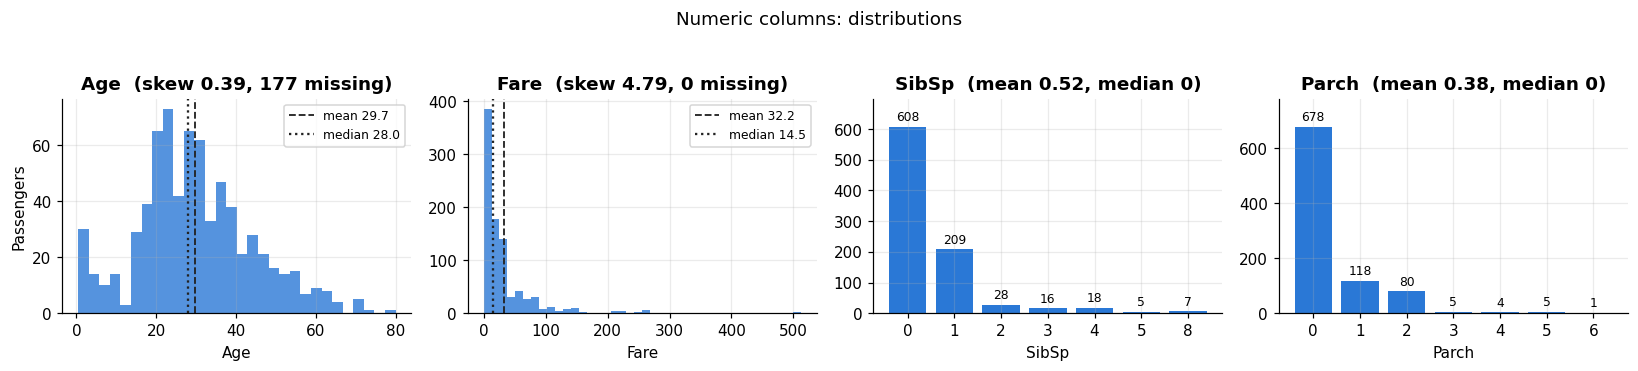

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

# Continuous columns: histogram with mean and median marked.
for ax, col, bins in [(axes[0], "Age", 30), (axes[1], "Fare", 40)]:
    s = df[col].dropna()
    ax.hist(s, bins=bins, color=C_NEUTRAL, alpha=0.8)
    ax.axvline(s.mean(), color="#222", ls="--", lw=1.2, label=f"mean {s.mean():.1f}")
    ax.axvline(s.median(), color="#222", ls=":", lw=1.5, label=f"median {s.median():.1f}")
    ax.set_title(f"{col}  (skew {s.skew():.2f}, {df[col].isna().sum()} missing)")
    ax.set_xlabel(col)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Passengers")

# Count columns: one bar per value; a histogram would blur the discrete steps.
for ax, col in [(axes[2], "SibSp"), (axes[3], "Parch")]:
    counts = df[col].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=C_NEUTRAL)
    ax.bar_label(bars, padding=2, fontsize=8)
    ax.set_title(f"{col}  (mean {df[col].mean():.2f}, median {df[col].median():.0f})")
    ax.set_xlabel(col)
    ax.margins(y=0.15)

fig.suptitle("Numeric columns: distributions", y=1.04)
plt.tight_layout()
plt.show()

Analysing Other Columns:

In [ ]:
# Analysing the rest of the cols

TEXT_COLS = ["PassengerId", "Name", "Ticket", "Cabin"]
text_report = pd.DataFrame({
    "dtype": df[TEXT_COLS].dtypes.astype(str),
    "unique": df[TEXT_COLS].nunique(),
    "missing": df[TEXT_COLS].isna().sum(),
    "unique_%_of_rows": (df[TEXT_COLS].nunique() / len(df) * 100).round(1),
    "examples": [", ".join(map(str, df[c].dropna().sample(3, random_state=0))) for c in TEXT_COLS],
})
display(text_report)



,dtype,unique,missing,unique_%_of_rows,examples
PassengerId,int64,891,0,100.0,"496, 649, 279"
Name,object,891,0,100.0,"Yousseff, Mr. Gerious, Willey, Mr. Edward, Ric..."
Ticket,object,681,0,76.4,"2627, S.O./P.P. 751, 382652"
Cabin,object,147,687,16.5,"A5, C83, A7"


"PassengerId" Column:

In [ ]:

print("Evaluating PassengerId")
ids = df["PassengerId"]
print(f"Unique: {ids.is_unique}   min: {ids.min()}   max: {ids.max()}   "
      f"consecutive 1..{len(df)}: {ids.tolist() == list(range(1, len(df) + 1))}")



Evaluating PassengerId
Unique: True   min: 1   max: 891   consecutive 1..891: True


"Name" Column:

Names without a recognisable title: 0


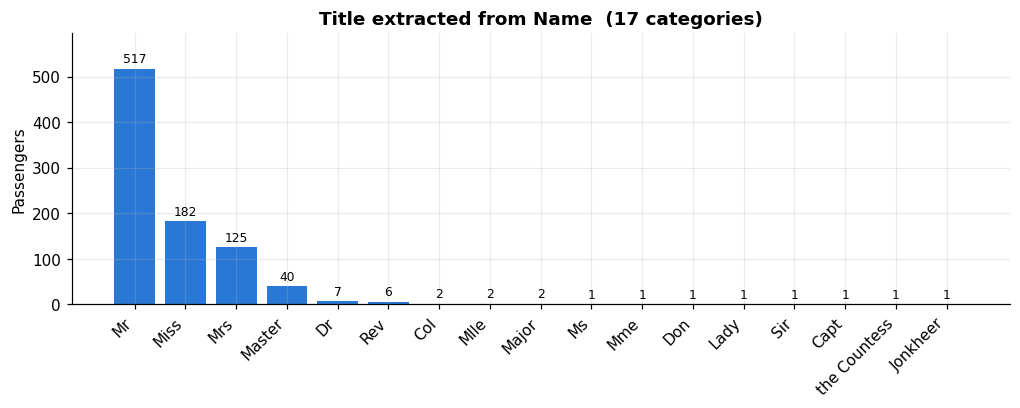

,passengers,sex,median_age,age_missing
Title,,,,
Mr,517,male,30.0,119
Miss,182,female,21.0,36
Mrs,125,female,35.0,17
Master,40,male,3.5,4
Dr,7,female/male,46.5,1
Rev,6,male,46.5,0
Mlle,2,female,24.0,0
Major,2,male,48.5,0
Col,2,male,58.0,0


In [ ]:
title = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print(f"Names without a recognisable title: {title.isna().sum()}")

title_counts = title.value_counts()
fig, ax = plt.subplots(figsize=(11, 3.2))
bars = ax.bar(title_counts.index, title_counts.values, color=C_NEUTRAL)
ax.bar_label(bars, padding=2, fontsize=8)
ax.set_title(f"Title extracted from Name  ({len(title_counts)} categories)")
ax.set_ylabel("Passengers")
ax.margins(y=0.15)
plt.xticks(rotation=45, ha="right")
plt.show()

display(pd.DataFrame({"Title": title, "Sex": df["Sex"], "Age": df["Age"]})
        .groupby("Title")
        .agg(passengers=("Sex", "size"),
             sex=("Sex", lambda s: "/".join(sorted(s.unique()))),
             median_age=("Age", "median"),
             age_missing=("Age", lambda a: a.isna().sum()))
        .sort_values("passengers", ascending=False))

"Ticket" Column:

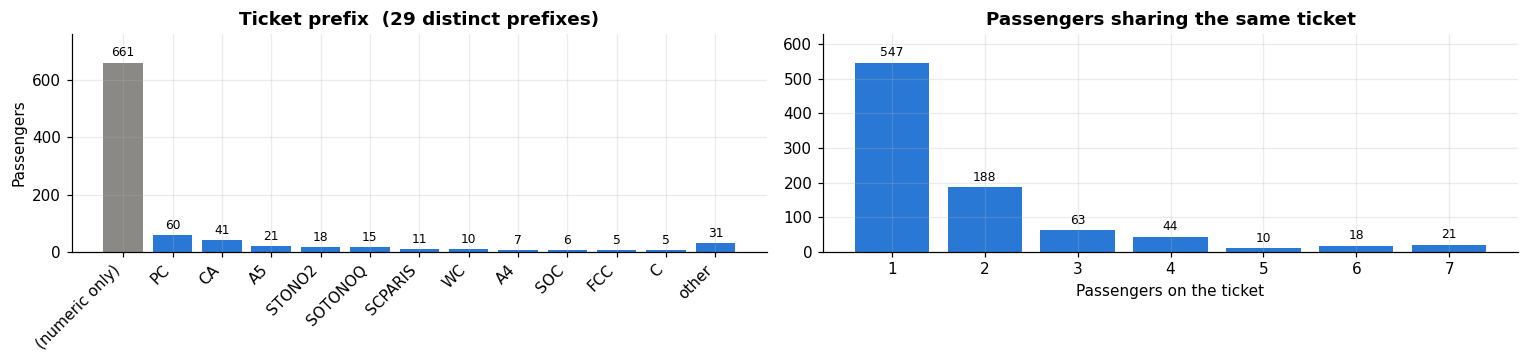

Distinct tickets: 681 for 891 passengers
Passengers sharing a ticket with someone: 344 (38.6%)


In [ ]:
ticket = df["Ticket"]
is_numeric = ticket.str.fullmatch(r"\d+")
prefix = (ticket.where(~is_numeric)
          .str.rsplit(" ", n=1).str[0]
          .str.replace(r"[\./ ]", "", regex=True).str.upper()
          .fillna("(numeric only)"))
group_size = ticket.map(ticket.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))

top_prefix = prefix.value_counts()
top_prefix = pd.concat([top_prefix.head(12), pd.Series({"other": top_prefix.iloc[12:].sum()})])
colors = [C_MISSING if p == "(numeric only)" else C_NEUTRAL for p in top_prefix.index]
bars = axes[0].bar(top_prefix.index, top_prefix.values, color=colors)
axes[0].bar_label(bars, padding=2, fontsize=8)
axes[0].set_title(f"Ticket prefix  ({prefix.nunique() - 1} distinct prefixes)")
axes[0].set_ylabel("Passengers")
axes[0].margins(y=0.15)
axes[0].tick_params(axis="x", rotation=45)
for lbl in axes[0].get_xticklabels():
    lbl.set_ha("right")

size_counts = group_size.value_counts().sort_index()
bars = axes[1].bar(size_counts.index.astype(str), size_counts.values, color=C_NEUTRAL)
axes[1].bar_label(bars, padding=2, fontsize=8)
axes[1].set_title("Passengers sharing the same ticket")
axes[1].set_xlabel("Passengers on the ticket")
axes[1].margins(y=0.15)
plt.tight_layout()
plt.show()

print(f"Distinct tickets: {ticket.nunique()} for {len(df)} passengers")
print(f"Passengers sharing a ticket with someone: {(group_size > 1).sum()} ({(group_size > 1).mean():.1%})")

"Cabin" Column:

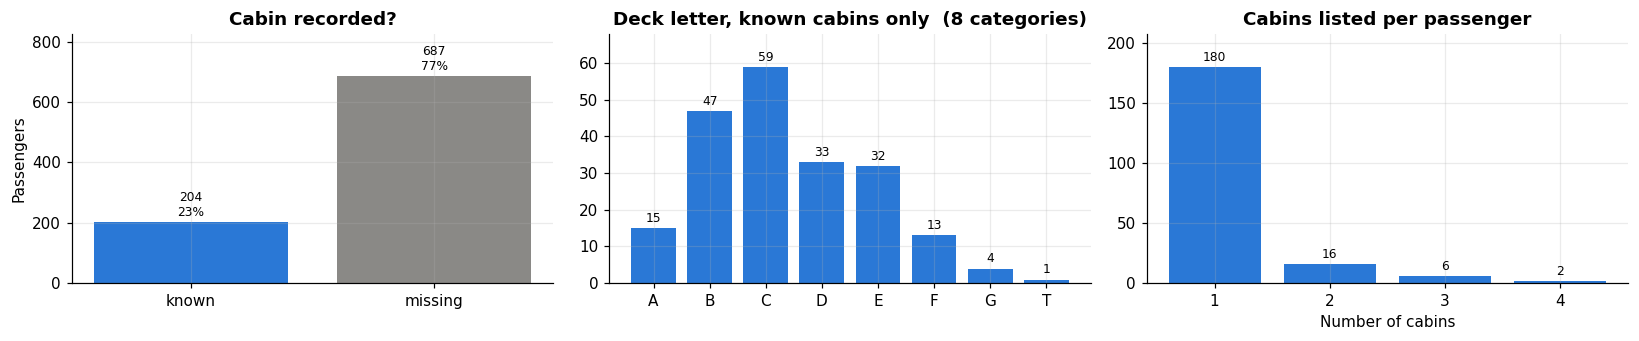

Cabin values not matching 'letter+number': ['F G73', 'F E69', 'D', 'D', 'T', 'D', 'F G63', 'F G73']


In [ ]:
cabin = df["Cabin"]
deck = cabin.str[0]
n_cabins = cabin.str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))

known = pd.Series({"known": cabin.notna().sum(), "missing": cabin.isna().sum()})
bars = axes[0].bar(known.index, known.values, color=[C_NEUTRAL, C_MISSING])
axes[0].bar_label(bars, labels=[f"{n}\n{n / len(df):.0%}" for n in known.values], padding=2, fontsize=8)
axes[0].set_title("Cabin recorded?")
axes[0].set_ylabel("Passengers")
axes[0].margins(y=0.2)

deck_counts = deck.value_counts().sort_index()
bars = axes[1].bar(deck_counts.index, deck_counts.values, color=C_NEUTRAL)
axes[1].bar_label(bars, padding=2, fontsize=8)
axes[1].set_title(f"Deck letter, known cabins only  ({len(deck_counts)} categories)")
axes[1].margins(y=0.15)

ncab = n_cabins.value_counts().sort_index()
bars = axes[2].bar(ncab.index.astype(int).astype(str), ncab.values, color=C_NEUTRAL)
axes[2].bar_label(bars, padding=2, fontsize=8)
axes[2].set_title("Cabins listed per passenger")
axes[2].set_xlabel("Number of cabins")
axes[2].margins(y=0.15)
plt.tight_layout()
plt.show()

# Cabin values that don't follow the usual "letter + number" pattern.
odd = cabin.dropna()[~cabin.dropna().str.fullmatch(r"([A-G]\d+\s?)+")]
print(f"Cabin values not matching 'letter+number': {odd.tolist()}")

Splitting into Train and Eval:

In [ ]:
# Train / validation split
SEED = 42          # fixed, so the split is identical on every run
VAL_SIZE = 0.2     # 20% held out for validation

train_df, val_df = train_test_split(
    df,
    test_size=VAL_SIZE,
    stratify=df["Survived"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

summary = pd.DataFrame({
    "rows": [len(df), len(train_df), len(val_df)],
    "survival_rate": [df["Survived"].mean(), train_df["Survived"].mean(), val_df["Survived"].mean()],
}, index=["full", "train", "validation"])
display(summary.round(3))

# From here on, analysis uses the training split only.
# val_df stays untouched until the model is evaluated.
eda_df = train_df

,rows,survival_rate
full,891,0.384
train,712,0.383
validation,179,0.385


**Advanced EDA ONLY on Train Split:**

Helper Functions:

In [ ]:
def wilson_ci(k, n, z=1.96):
    """95% confidence interval for a proportion k/n (Wilson method, reliable for small n)."""
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)


def survival_by(values: pd.Series, data: pd.DataFrame) -> pd.DataFrame:
    """Passengers, survival rate and 95% CI for each distinct value (missing shown as 'missing')."""
    key = values.astype(object).where(values.notna(), "missing")
    g = data.groupby(key, sort=False)["Survived"].agg(n="size", survived="sum")
    g["rate"] = g["survived"] / g["n"]
    g["ci_low"], g["ci_high"] = zip(*[wilson_ci(k, n) for k, n in zip(g["survived"], g["n"])])
    return g


def cramers_v(values: pd.Series, target: pd.Series) -> tuple[float, float]:
    """Association strength (0 = none, 1 = perfect) and chi-square p-value."""
    table = pd.crosstab(values.astype(object).where(values.notna(), "missing"), target)
    chi2, p, _, _ = chi2_contingency(table)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p


def plot_survival(ax, stats: pd.DataFrame, title: str, overall: float) -> None:
    labels = [str(i) for i in stats.index]
    colors = [C_MISSING if l == "missing" else C_SURVIVED for l in labels]
    rate = stats["rate"].values
    err = np.vstack([rate - stats["ci_low"].values, stats["ci_high"].values - rate])
    ax.bar([f"{l}\nn={n}" for l, n in zip(labels, stats["n"])], rate,
           color=colors, yerr=err, capsize=3, ecolor="#555", error_kw={"lw": 1})
    ax.axhline(overall, color="#555", ls="--", lw=1)
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8)


# ---- Measures for relationships between any two features ----

def cramers_v_corrected(x: pd.Series, y: pd.Series) -> float:
    """Bias-corrected Cramér's V (Bergsma 2013): not inflated by many small categories."""
    table = pd.crosstab(x.astype(object).where(x.notna(), "missing"),
                        y.astype(object).where(y.notna(), "missing"))
    n = table.values.sum()
    r, k = table.shape
    if r < 2 or k < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))


def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    """Eta: share of a numeric column's spread explained by a categorical column (0 to 1)."""
    mask = values.notna()
    cats, vals = categories[mask].astype(object).fillna("missing"), values[mask]
    overall_mean = vals.mean()
    between = sum(len(g) * (g.mean() - overall_mean) ** 2 for _, g in vals.groupby(cats))
    total = ((vals - overall_mean) ** 2).sum()
    return np.sqrt(between / total) if total > 0 else np.nan


def association(x: pd.Series, y: pd.Series, x_numeric: bool, y_numeric: bool) -> float:
    """Pick the right measure for the pair of column types."""
    if x_numeric and y_numeric:
        mask = x.notna() & y.notna()
        return abs(spearmanr(x[mask], y[mask]).statistic)
    if x_numeric:
        return correlation_ratio(y, x)
    if y_numeric:
        return correlation_ratio(x, y)
    return cramers_v_corrected(x, y)


def survival_heatmap(ax, rows: pd.Series, cols: pd.Series, data: pd.DataFrame,
                     row_order: list, col_order: list, title: str) -> pd.DataFrame:
    """Survival rate for every combination of two features, with group size and 95% CI in each cell."""
    key_r = rows.astype(object).where(rows.notna(), "missing")
    key_c = cols.astype(object).where(cols.notna(), "missing")
    g = data.groupby([key_r, key_c])["Survived"].agg(n="size", survived="sum")
    g["rate"] = g["survived"] / g["n"]
    g["ci_low"], g["ci_high"] = zip(*[wilson_ci(k, n) for k, n in zip(g["survived"], g["n"])])
    rate = g["rate"].unstack().reindex(index=row_order, columns=col_order)
    n = g["n"].unstack().reindex(index=row_order, columns=col_order)

    im = ax.imshow(rate.values.astype(float), cmap="Blues", vmin=0, vmax=1)
    for i, r in enumerate(row_order):
        for j, c in enumerate(col_order):
            if pd.isna(rate.loc[r, c]):
                ax.text(j, i, "no passengers", ha="center", va="center", fontsize=8, color="#888")
                continue
            lo, hi = g.loc[(r, c), ["ci_low", "ci_high"]]
            ax.text(j, i, f"{rate.loc[r, c]:.0%}\n({lo:.0%}–{hi:.0%})\nn={int(n.loc[r, c])}",
                    ha="center", va="center", fontsize=9,
                    color="white" if rate.loc[r, c] > 0.6 else "#222")
    ax.set_xticks(range(len(col_order)), col_order)
    ax.set_yticks(range(len(row_order)), row_order)
    ax.set_xlabel(cols.name)
    ax.set_ylabel(rows.name)
    ax.set_title(title)
    ax.grid(False)
    return g

In [ ]:
# Overall survival rate of the EDA data (training split)

OVERALL_SURVIVAL = eda_df["Survived"].mean()
n_survived = int(eda_df["Survived"].sum())
low, high = wilson_ci(n_survived, len(eda_df))
print(f"Overall survival rate: {OVERALL_SURVIVAL:.1%} "
      f"({n_survived} of {len(eda_df)} passengers, 95% CI {low:.1%} to {high:.1%})")

Overall survival rate: 38.3% (273 of 712 passengers, 95% CI 34.8% to 42.0%)


Survival Rate for Categorical and Count Features:

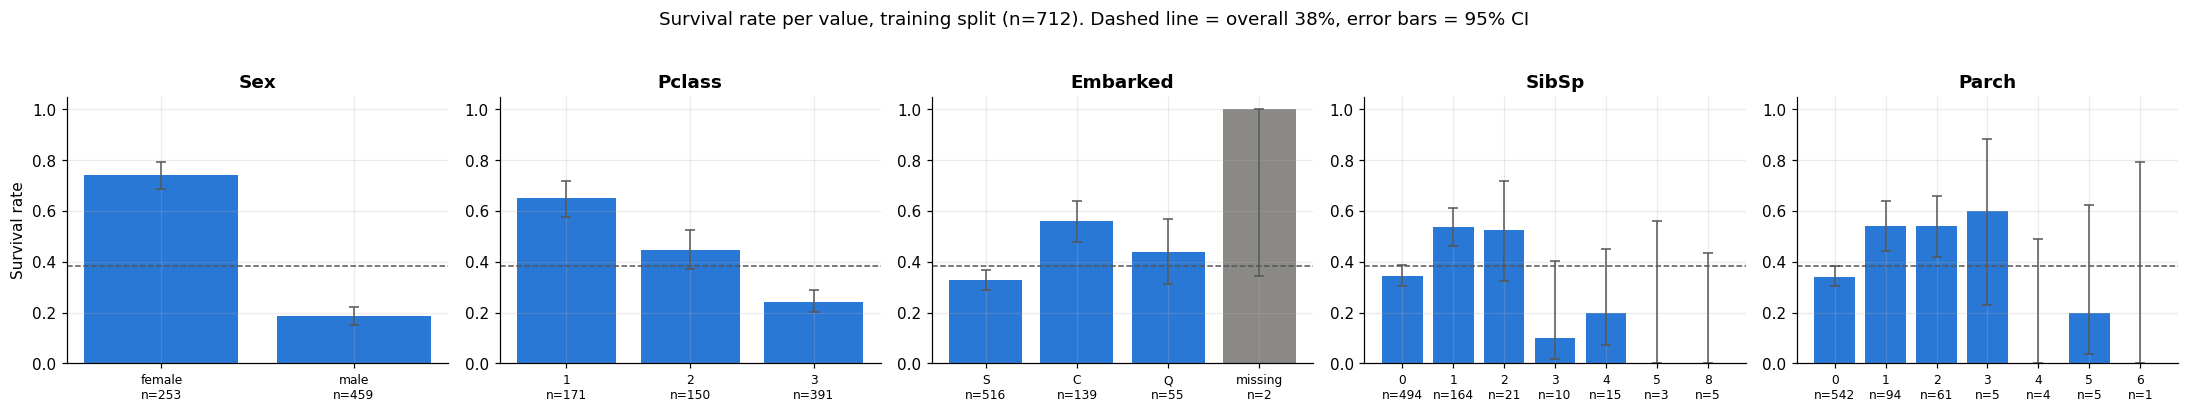

In [ ]:
d = eda_df

CATEGORICAL = {
    "Sex": ["female", "male"],
    "Pclass": [1, 2, 3],
    "Embarked": ["S", "C", "Q", "missing"],
    "SibSp": sorted(d["SibSp"].unique()),
    "Parch": sorted(d["Parch"].unique()),
}

fig, axes = plt.subplots(1, len(CATEGORICAL), figsize=(20, 3.6))
for ax, (col, order) in zip(axes, CATEGORICAL.items()):
    stats = survival_by(d[col], d)
    plot_survival(ax, stats.reindex([o for o in order if o in stats.index]), col, OVERALL_SURVIVAL)
axes[0].set_ylabel("Survival rate")
fig.suptitle(f"Survival rate per value, training split (n={len(d)}). "
             f"Dashed line = overall {OVERALL_SURVIVAL:.0%}, error bars = 95% CI", y=1.03)
plt.tight_layout()
plt.show()

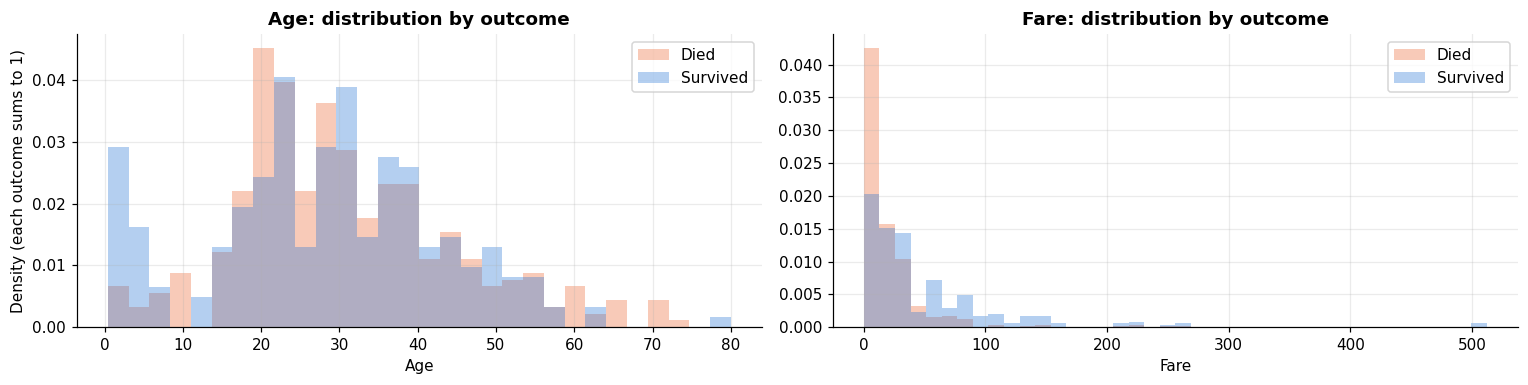

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, col, bins in [(axes[0], "Age", 30), (axes[1], "Fare", 40)]:
    edges = np.histogram_bin_edges(eda_df[col].dropna(), bins=bins)
    for outcome, color, label in [(0, C_DIED, "Died"), (1, C_SURVIVED, "Survived")]:
        ax.hist(eda_df.loc[eda_df["Survived"] == outcome, col].dropna(), bins=edges, density=True,
                color=color, alpha=0.35, histtype="stepfilled", ec=color, lw=1.2, label=label)
    ax.set_title(f"{col}: distribution by outcome")
    ax.set_xlabel(col)
    ax.legend()
axes[0].set_ylabel("Density (each outcome sums to 1)")
plt.tight_layout()
plt.show()

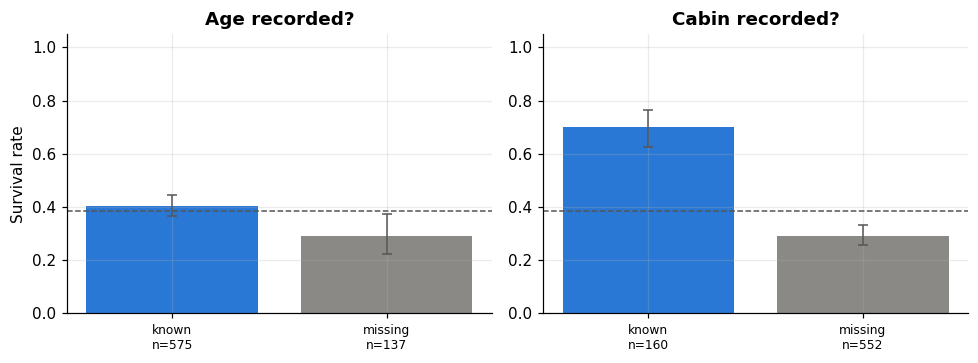

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col in zip(axes, ["Age", "Cabin"]):
    known = eda_df[col].notna().map({True: "known", False: "missing"})
    stats = survival_by(known, eda_df).reindex(["known", "missing"])
    plot_survival(ax, stats, f"{col} recorded?", OVERALL_SURVIVAL)
axes[0].set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

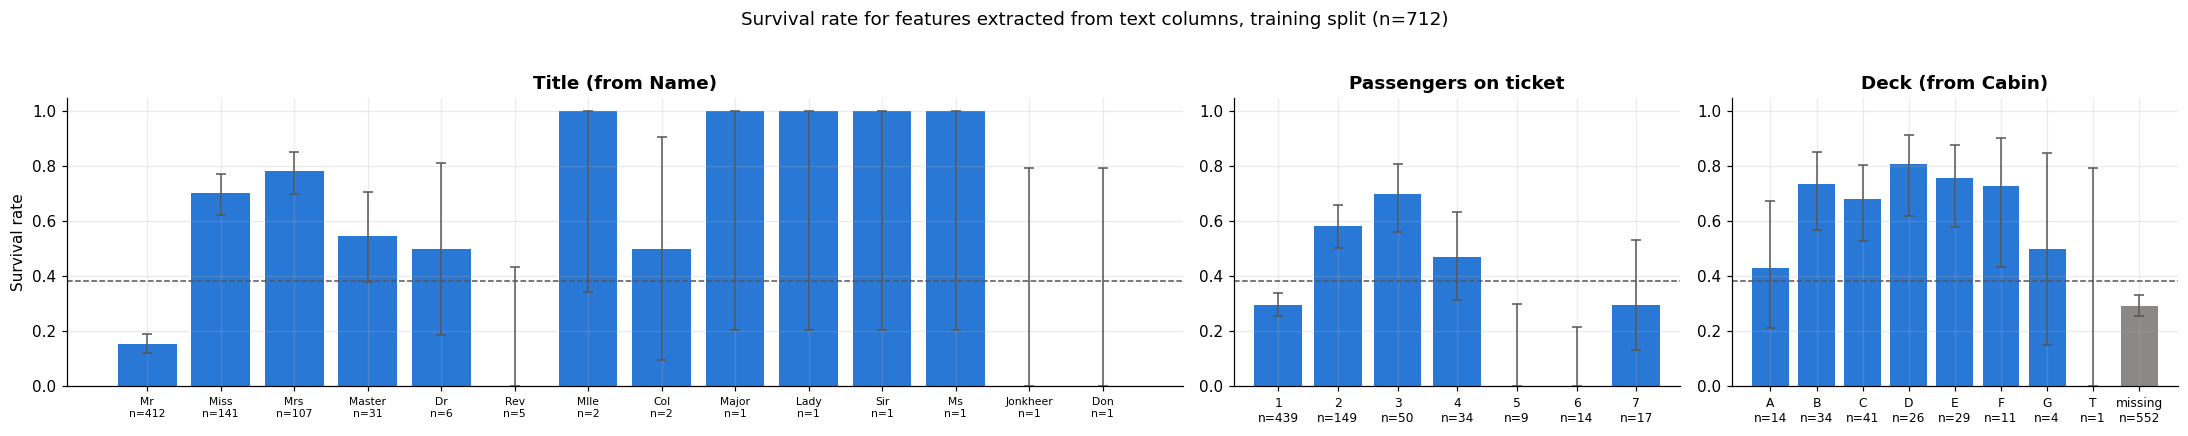

In [ ]:
d = eda_df

title = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
ticket_count = d["Ticket"].map(df["Ticket"].value_counts())   # passengers on the same ticket
deck = d["Cabin"].str[0]

EXTRACTED = {
    "Title (from Name)": (title, title.value_counts().index.tolist()),
    "Passengers on ticket": (ticket_count, sorted(ticket_count.unique())),
    "Deck (from Cabin)": (deck, sorted(deck.dropna().unique()) + ["missing"]),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 3.8), gridspec_kw={"width_ratios": [2.5, 1, 1]})
for ax, (name, (values, order)) in zip(axes, EXTRACTED.items()):
    stats = survival_by(values, d)
    plot_survival(ax, stats.reindex([o for o in order if o in stats.index]), name, OVERALL_SURVIVAL)
axes[0].set_ylabel("Survival rate")
axes[0].tick_params(axis="x", labelsize=7)
fig.suptitle(f"Survival rate for features extracted from text columns, training split (n={len(d)})", y=1.03)
plt.tight_layout()
plt.show()

In [ ]:
d = eda_df
is_numeric = d["Ticket"].str.fullmatch(r"\d+")
prefix = (d["Ticket"].where(~is_numeric)
          .str.rsplit(" ", n=1).str[0]
          .str.replace(r"[\./ ]", "", regex=True).str.upper()
          .fillna("(numeric)"))

# Survival per prefix, with the classes and ports each prefix belongs to.
stats = survival_by(prefix, d)
prefix_table = (d.assign(prefix=prefix)
                 .groupby("prefix")
                 .agg(classes=("Pclass", lambda s: ", ".join(map(str, sorted(s.unique())))),
                      ports=("Embarked", lambda s: ", ".join(sorted(s.dropna().unique())))))
prefix_table = (stats[["n", "rate", "ci_low", "ci_high"]]
                .join(prefix_table)
                .rename(columns={"n": "passengers", "rate": "survival_rate"})
                .sort_values("passengers", ascending=False))
display(prefix_table.head(12).round(2))

for other in ["Survived", "Pclass", "Embarked"]:
    print(f"Ticket prefix vs {other}: Cramér's V (corrected) = {cramers_v_corrected(prefix, d[other]):.2f}")

,passengers,survival_rate,ci_low,ci_high,classes,ports
Ticket,,,,,,
(numeric),522,0.39,0.35,0.43,"1, 2, 3","C, Q, S"
PC,54,0.63,0.50,0.75,1,"C, S"
CA,32,0.31,0.18,0.49,"2, 3",S
A5,20,0.10,0.03,0.30,3,"Q, S"
STONO2,14,0.43,0.21,0.67,3,S
SOTONOQ,11,0.18,0.05,0.48,3,S
WC,10,0.10,0.02,0.40,"2, 3",S
SCPARIS,9,0.56,0.27,0.81,2,C
A4,6,0.00,0.00,0.39,3,S


Ticket prefix vs Survived: Cramér's V (corrected) = 0.18
Ticket prefix vs Pclass: Cramér's V (corrected) = 0.46
Ticket prefix vs Embarked: Cramér's V (corrected) = 0.26


Association Matrix:

/tmp/ipykernel_895/517363851.py:59: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cats, vals = categories[mask].astype(object).fillna("missing"), values[mask]
/tmp/ipykernel_895/517363851.py:59: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cats, vals = categories[mask].astype(object).fillna("missing"), values[mask]
/tmp/ipykernel_895/517363851.py:59: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, 

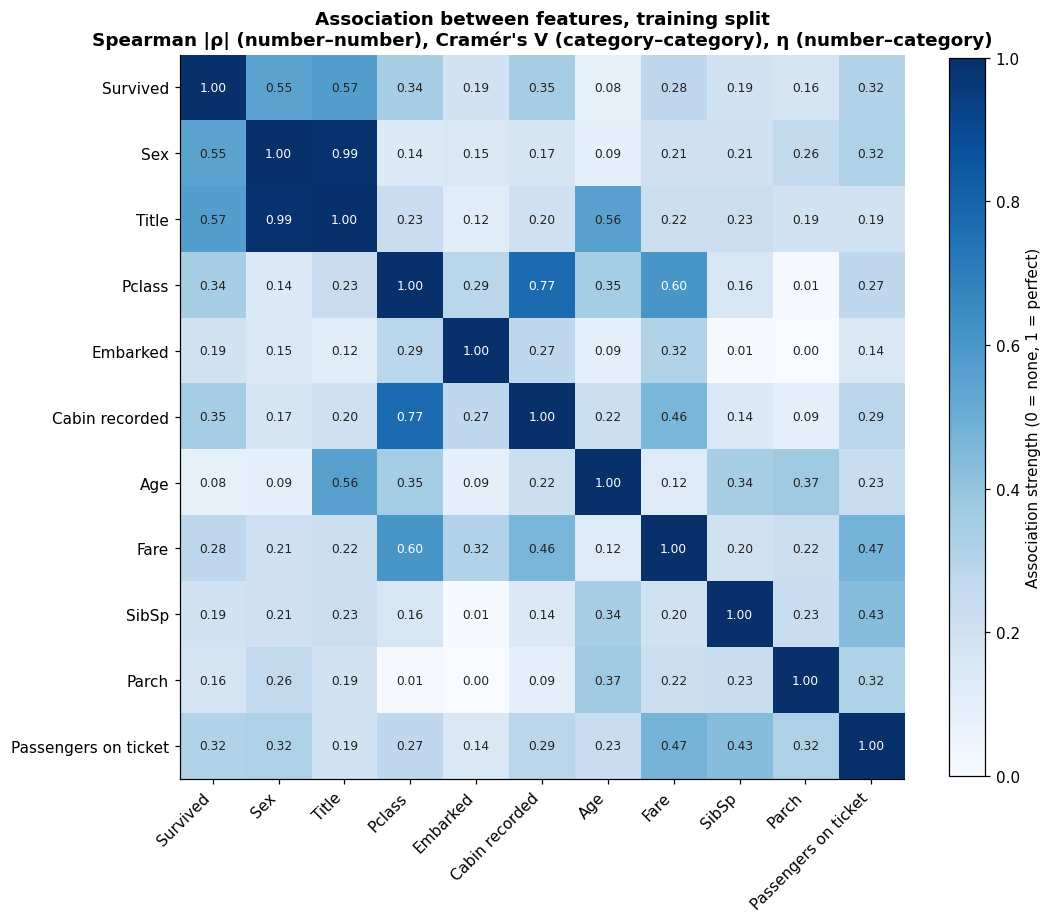

In [ ]:
d = eda_df
title = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

FEATURES = {               # name: (values, is_numeric)
    "Survived": (d["Survived"], False),
    "Sex": (d["Sex"], False),
    "Title": (title, False),
    "Pclass": (d["Pclass"], False),
    "Embarked": (d["Embarked"], False),
    "Cabin recorded": (d["Cabin"].notna(), False),
    "Age": (d["Age"], True),
    "Fare": (d["Fare"], True),
    "SibSp": (d["SibSp"], False),
    "Parch": (d["Parch"], False),
    "Passengers on ticket": (d["Ticket"].map(df["Ticket"].value_counts()), False),
}
names = list(FEATURES)
matrix = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        xa, na = FEATURES[a]
        xb, nb = FEATURES[b]
        matrix.loc[a, b] = 1.0 if a == b else association(xa, xb, na, nb)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(matrix.values.astype(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        val = matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                color="white" if val > 0.6 else "#222")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="Association strength (0 = none, 1 = perfect)")
ax.set_title("Association between features, training split\n"
             "Spearman |ρ| (number–number), Cramér's V (category–category), η (number–category)")
plt.tight_layout()
plt.show()

Analysing "Cabin Recorded":

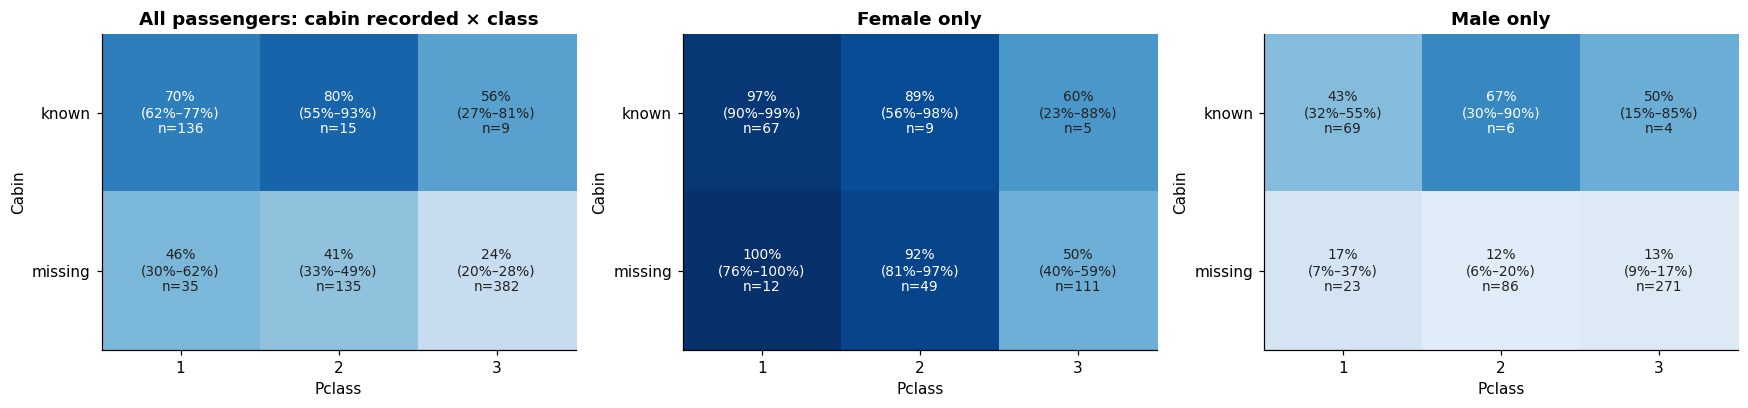

In [ ]:
d = eda_df
cabin = d["Cabin"].notna().map({True: "known", False: "missing"}).rename("Cabin")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
survival_heatmap(axes[0], cabin, d["Pclass"], d, ["known", "missing"], [1, 2, 3],
                 "All passengers: cabin recorded × class")
for ax, sex in zip(axes[1:], ["female", "male"]):
    sub = d[d["Sex"] == sex]
    survival_heatmap(ax, cabin[sub.index], sub["Pclass"], sub, ["known", "missing"], [1, 2, 3],
                     f"{sex.capitalize()} only")
plt.tight_layout()
plt.show()

Further Analysis of Age and Fare by Sex and Class:

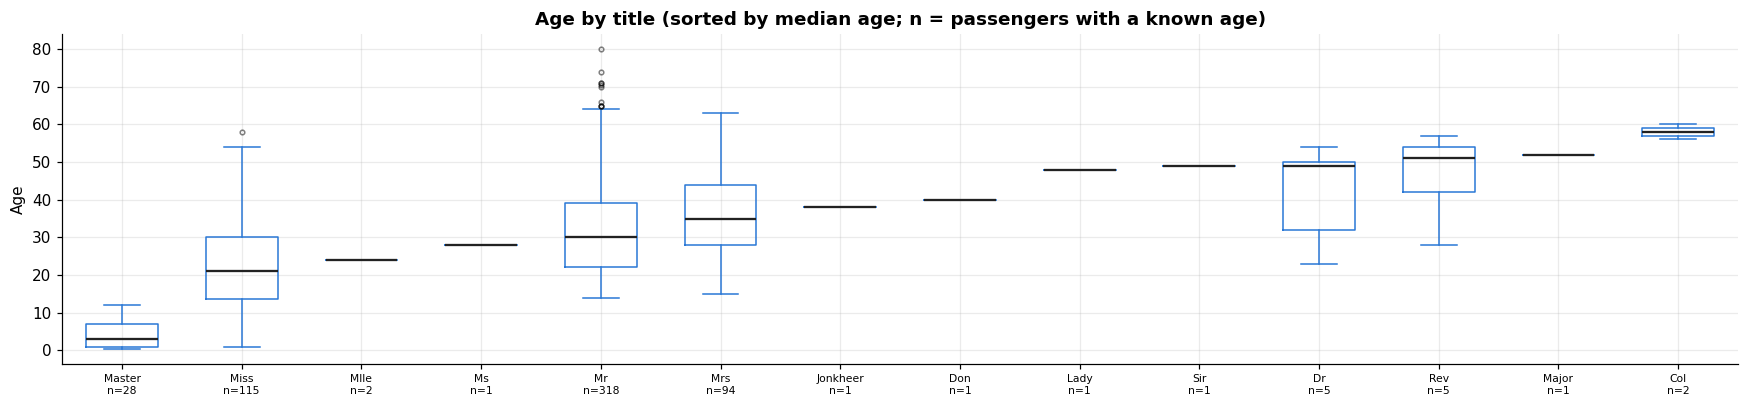

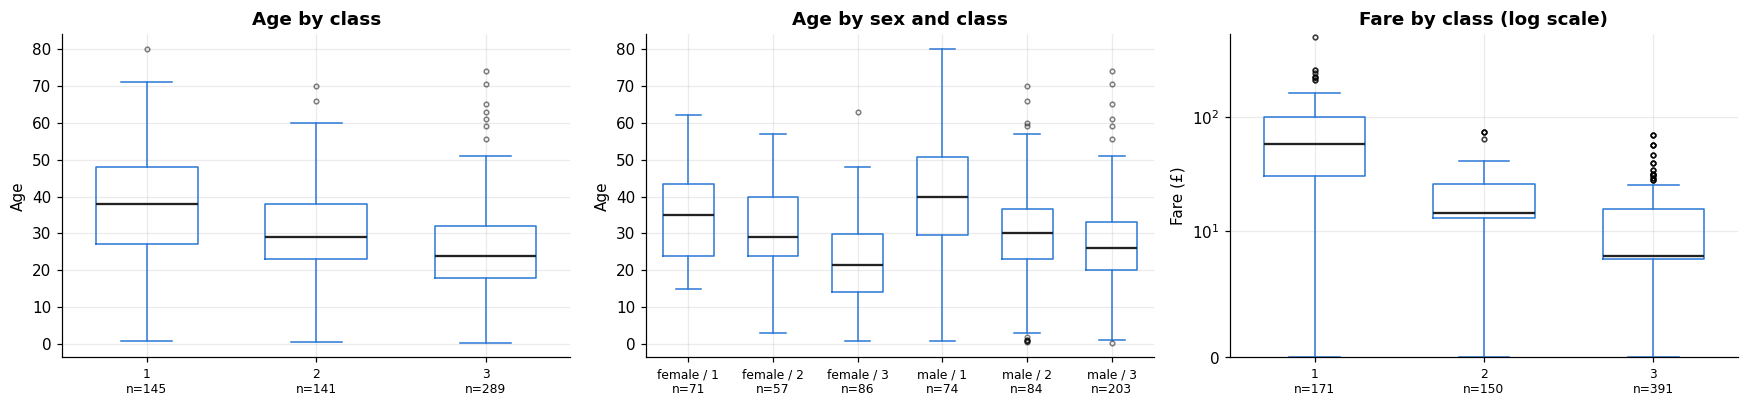

In [ ]:
def boxplot_by(ax, values: pd.Series, groups: pd.Series, order: list, title: str, ylabel: str) -> None:
    """One box per group, with group size under each label. Missing values are left out."""
    data = [values[(groups == g) & values.notna()] for g in order]
    ax.boxplot(data, widths=0.6, medianprops={"color": "#222", "lw": 1.5},
               boxprops={"color": C_NEUTRAL}, whiskerprops={"color": C_NEUTRAL},
               capprops={"color": C_NEUTRAL}, flierprops={"markersize": 3, "alpha": 0.5})
    ax.set_xticks(range(1, len(order) + 1), [f"{g}\nn={len(x)}" for g, x in zip(order, data)])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelsize=8)

d = eda_df
title_order = d.assign(title=title).groupby("title")["Age"].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(16, 3.8))
boxplot_by(ax, d["Age"], title, title_order,
           "Age by title (sorted by median age; n = passengers with a known age)", "Age")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sex_class = d["Sex"] + " / " + d["Pclass"].astype(str)
boxplot_by(axes[0], d["Age"], d["Pclass"], [1, 2, 3], "Age by class", "Age")
boxplot_by(axes[1], d["Age"], sex_class,
           ["female / 1", "female / 2", "female / 3", "male / 1", "male / 2", "male / 3"],
           "Age by sex and class", "Age")
boxplot_by(axes[2], d["Fare"], d["Pclass"], [1, 2, 3], "Fare by class (log scale)", "Fare (£)")
axes[2].set_yscale("symlog", linthresh=10)
axes[2].set_ylim(bottom=0)
plt.tight_layout()
plt.show()



In [ ]:
print("Share of each class per port (rows sum to 100%):")
display((pd.crosstab(d["Embarked"], d["Pclass"], normalize="index") * 100).round(0))
print("Share of passengers with a recorded cabin, per class (%):")
display((d.groupby("Pclass")["Cabin"].apply(lambda c: c.notna().mean()) * 100).round(0).to_frame("cabin_recorded_%"))
print("Title by sex:")
display(pd.crosstab(title, d["Sex"]))
print("Missing ages per title:")
display(d["Age"].isna().groupby(title).sum().loc[lambda s: s > 0].to_frame("missing_age"))

Share of each class per port (rows sum to 100%):


Pclass,1,2,3
Embarked,,,
C,53.0,9.0,38.0
Q,2.0,4.0,95.0
S,18.0,26.0,55.0


Share of passengers with a recorded cabin, per class (%):


,cabin_recorded_%
Pclass,
1,80.0
2,10.0
3,2.0


Title by sex:


Sex,female,male
Name,,
Col,0,2
Don,0,1
Dr,1,5
Jonkheer,0,1
Lady,1,0
Major,0,1
Master,0,31
Miss,141,0
Mlle,2,0


Missing ages per title:


,missing_age
Name,
Dr,1
Master,3
Miss,26
Mr,94
Mrs,13


Further Analysis of Survival by Sex, Class and Port:

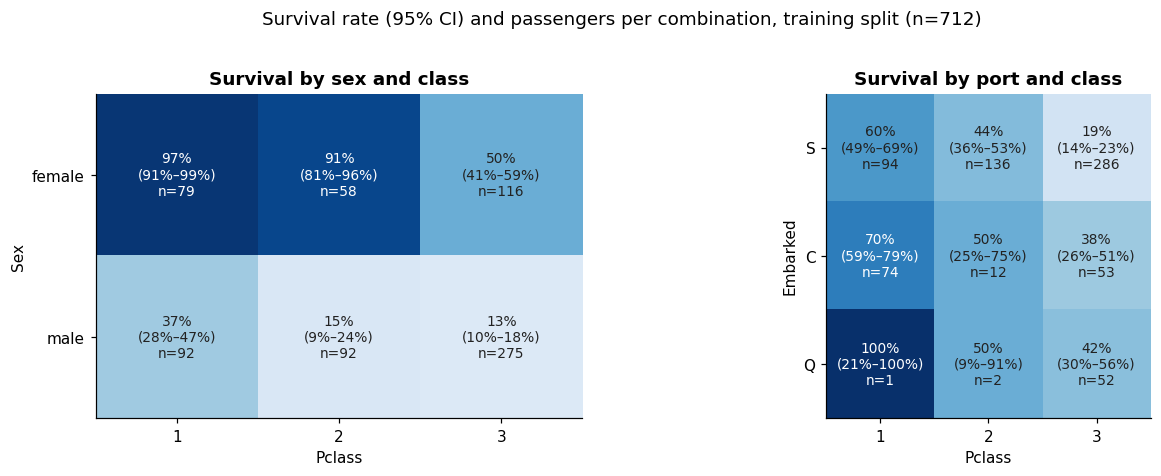

In [ ]:
d = eda_df
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
survival_heatmap(axes[0], d["Sex"], d["Pclass"], d, ["female", "male"], [1, 2, 3],
                 "Survival by sex and class")
survival_heatmap(axes[1], d["Embarked"], d["Pclass"], d, ["S", "C", "Q"], [1, 2, 3],
                 "Survival by port and class")
fig.suptitle(f"Survival rate (95% CI) and passengers per combination, training split (n={len(d)})", y=1.02)
plt.tight_layout()
plt.show()

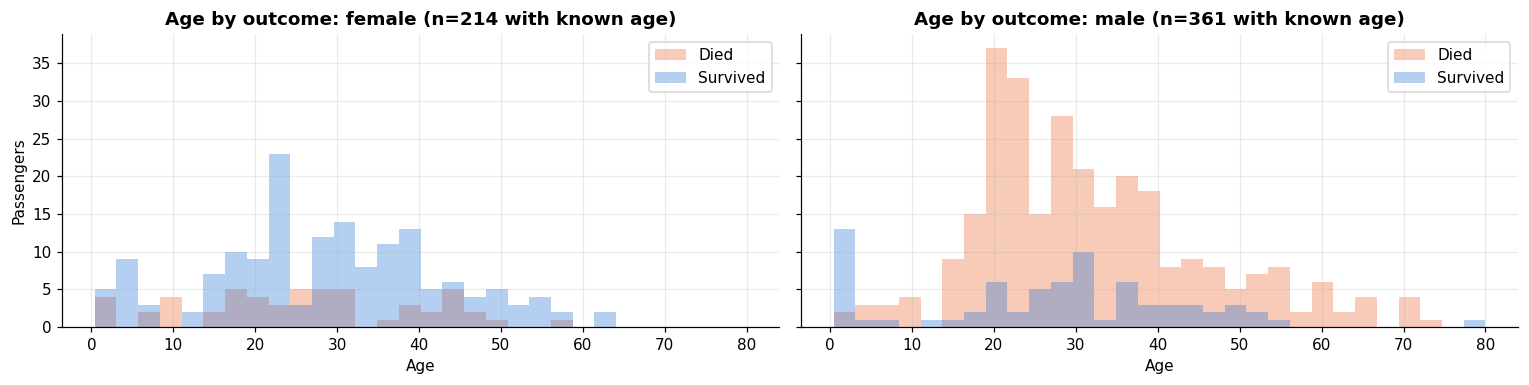

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
edges = np.histogram_bin_edges(d["Age"].dropna(), bins=30)
for ax, sex in zip(axes, ["female", "male"]):
    sub = d[d["Sex"] == sex]
    for outcome, color, label in [(0, C_DIED, "Died"), (1, C_SURVIVED, "Survived")]:
        ax.hist(sub.loc[sub["Survived"] == outcome, "Age"].dropna(), bins=edges,
                color=color, alpha=0.35, histtype="stepfilled", ec=color, lw=1.2, label=label)
    ax.set_title(f"Age by outcome: {sex} (n={sub['Age'].notna().sum()} with known age)")
    ax.set_xlabel("Age")
    ax.legend()
axes[0].set_ylabel("Passengers")
plt.tight_layout()
plt.show()

Exploring Link between Title and Age:

In [ ]:
title = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

# Child cutoff taken from the data: "Master" is the title for boys.
CHILD_AGE_LIMIT = d.loc[title == "Master", "Age"].max() + 1
print(f"Oldest 'Master' in the training split: {CHILD_AGE_LIMIT - 1:.0f}, so 'child' may = under {CHILD_AGE_LIMIT:.0f}")
d = eda_df
title = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
male = d["Sex"] == "male"

# Boys: does "Master" match "male under 13" in both directions?
master_age = d.loc[title == "Master", "Age"]
print(f"Master ages: {master_age.min():.1f} to {master_age.max():.0f} (median {master_age.median():.0f}); "
      f"{master_age.isna().sum()} with unknown age")
print("Titles of males under 13:", title[male & (d["Age"] < 13)].value_counts().to_dict())
print(f"Youngest 'Mr': {d.loc[title == 'Mr', 'Age'].min():.0f}")

# Girls: "Miss" covers all ages, but travelling with parents is a strong clue.
miss = d[title == "Miss"]
print(f"\nMiss with known age: {miss['Age'].notna().sum()}, of whom under 13: {(miss['Age'] < 13).sum()}")
display(miss.groupby(miss["Parch"] > 0)["Age"]
            .agg(passengers="count", median_age="median", min_age="min", max_age="max")
            .rename(index={False: "no parents/children aboard", True: "with parents/children (Parch > 0)"}))
print(f"Miss with unknown age travelling with parents/children: "
      f"{(miss['Age'].isna() & (miss['Parch'] > 0)).sum()} of {miss['Age'].isna().sum()}")

Oldest 'Master' in the training split: 12, so 'child' may = under 13
Master ages: 0.4 to 12 (median 3); 3 with unknown age
Titles of males under 13: {'Master': 28}
Youngest 'Mr': 14

Miss with known age: 115, of whom under 13: 27


,passengers,median_age,min_age,max_age
Parch,,,,
no parents/children aboard,72,26.0,5.00,58.0
with parents/children (Parch > 0),43,8.0,0.75,39.0


Miss with unknown age travelling with parents/children: 6 of 26


Oldest 'Master' in the training split: 12, so 'child' = under 13


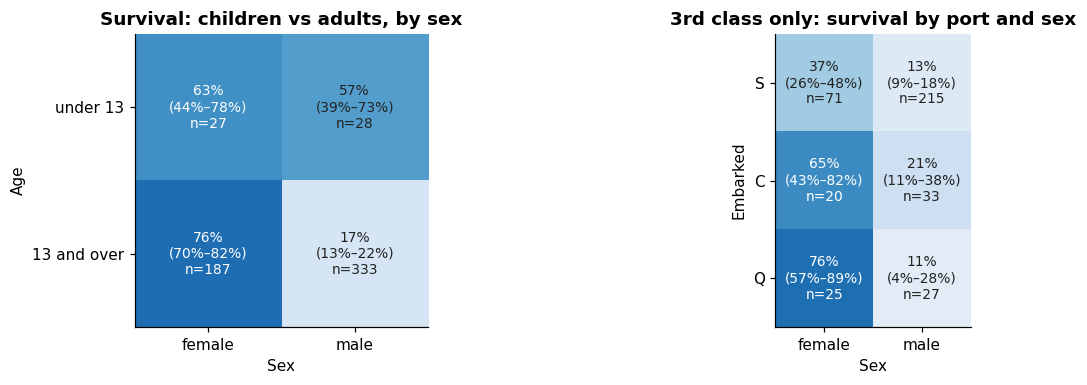

Class of female passengers, children vs adults (rows sum to 100%):


Pclass,1,2,3
Age,,,
13 and over,38.0,27.0,35.0
under 13,0.0,26.0,74.0


Share of women among 3rd-class passengers, per port:


,female_share
Embarked,
C,0.38
Q,0.48
S,0.25


In [ ]:

child_label, adult_label = f"under {CHILD_AGE_LIMIT:.0f}", f"{CHILD_AGE_LIMIT:.0f} and over"
age_group = (d["Age"].lt(CHILD_AGE_LIMIT)
             .map({True: child_label, False: adult_label})
             .where(d["Age"].notna())            # unknown age stays missing
             .rename("Age"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
survival_heatmap(axes[0], age_group, d["Sex"], d, [child_label, adult_label],
                 ["female", "male"], "Survival: children vs adults, by sex")
third = d[d["Pclass"] == 3]
survival_heatmap(axes[1], third["Embarked"], third["Sex"], third, ["S", "C", "Q"], ["female", "male"],
                 "3rd class only: survival by port and sex")
plt.tight_layout()
plt.show()

print("Class of female passengers, children vs adults (rows sum to 100%):")
display((pd.crosstab(age_group[d["Sex"] == "female"], d.loc[d["Sex"] == "female", "Pclass"],
                     normalize="index") * 100).round(0))
print("Share of women among 3rd-class passengers, per port:")
display(third.groupby("Embarked")["Sex"].apply(lambda s: (s == "female").mean()).round(2).to_frame("female_share"))

# EDA summary

## Data and method

- **Source:** `train.csv` from the Kaggle Titanic competition, fetched with `kagglehub`: 891 passengers, 12 columns.
- **Part 1 (data audit)** uses the full file. These checks describe data quality and the shape of each column without using the target.
- **Part 2 (relationships with survival)** uses only the training split: a stratified 80/20 split with seed 42 (712 training, 179 validation passengers, survival rate 38.3% vs 38.5%). The validation split stays untouched until the model is evaluated, so that it measures performance on genuinely unseen data.
- Survival rates are shown with 95% Wilson confidence intervals, which stay reliable for small groups. Association strength uses bias-corrected Cramér's V (two categories), the correlation ratio η (number and category) and Spearman |ρ| (two numbers), all on a 0–1 scale.

## Part 1: data audit

- **Integrity:** no duplicate rows (also checked ignoring PassengerId); PassengerId is a unique 1–891 sequence. All values fall in their valid ranges: Survived ∈ {0, 1}, Pclass ∈ {1, 2, 3}, Sex ∈ {male, female}, Embarked ∈ {S, C, Q}, and no negative ages, fares or counts.
- **Missing values:**
  - Cabin: 687 (77%)
  - Age: 177 (20%)
  - Embarked: 2 (0.2%)
  - Only 183 passengers (21%) have no missing value at all, so dropping incomplete rows is not an option.
  - Age and Cabin are often missing together (158 passengers).
- **Hidden missing values:** 15 passengers have a fare of 0, mostly on staff-style tickets ("LINE") and a few ticket series. These are treated as missing, not as free travel.
- **Distributions:**
  - **Age** is nearly symmetric (mean 29.7, median 28, skew 0.39).
  - **Fare** is strongly right-skewed (mean 32.2 vs median 14.45, skew 4.79, max 512); a log transform reduces its skew to 0.39.
  - **SibSp and Parch** are mostly 0 (68% and 76% of passengers).
- **Text columns:** Name, Ticket and Cabin are near-unique identifiers, but contain usable information:
  - a title in every name (17 distinct titles)
  - shared tickets (39% of passengers share one with someone)
  - a deck letter in each recorded cabin
  - Ticket is stored as text because 26% of tickets carry a letter prefix.

## Part 2: relationships with survival (training split)

**Strongest single features**

| Feature | Association | Survival range |
|---|---|---|
| Title | 0.57 | 15% (Mr) to 79% (Mrs) |
| Sex | 0.55 | 19% (male) to 74% (female) |
| Fare | 0.41 (rank-biserial) | median £10.50 (died) vs £26 (survived) |
| Cabin recorded | 0.35 | 29% (missing) to 70% (known) |
| Pclass | 0.34 | 24% (3rd) to 65% (1st) |
| Passengers on ticket | 0.32 | 30% alone, 59–70% in groups of 2–3, lower above that |

**Weaker features:** SibSp, Parch and Embarked (0.16–0.21). Age shows almost no overall association (0.08, medians 28 vs 29), but its effect is concentrated at one end of the range (see interactions). Whether a ticket carries a prefix makes no difference (39% vs 37%). Individual prefixes do differ, but each corresponds closely to one class and port (prefix vs Pclass V = 0.46, vs survival 0.18).

**Overlaps between features**

- **Sex and Title** are almost the same variable (V = 0.99); Title additionally encodes age group (η = 0.56). Median ages: Master 3, Miss 21, Mr 30, Mrs 35.
- **Title as a child indicator:** for boys it is exact. All males under 13 are titled "Master", and the youngest "Mr" is 14. For girls there is no equivalent: "Miss" covers ages 0.8–58, but a Miss travelling with parents or children (Parch > 0) has a median age of 8, against 26 without.
- **Pclass, Fare and Cabin recorded** all measure wealth. A cabin is recorded for 80% of 1st-class passengers but only 10% of 2nd and 2% of 3rd (V = 0.77); median fares are £58, £14.50 and £8 (η = 0.60).
- **Age** relates to Title (η = 0.56) more strongly than to Pclass (0.35).
- **SibSp, Parch and passengers on ticket** overlap (0.23–0.43).
- **Embarked** reflects class mix: Cherbourg 53% 1st class, Queenstown 95% 3rd class.

**Interactions**

- **Sex × class:** class affects men and women differently. Women: 97% (1st), 91% (2nd), 50% (3rd). Men: 37%, 15%, 13%. For women the drop comes between 2nd and 3rd class, for men between 1st and 2nd.
- **Age × sex:** boys under 13 survived at 57% vs 17% for older males (the cutoff comes from the data: the oldest "Master" is 12). Girls under 13 survived at 63%, below adult women (76%), because 74% of girls travelled in 3rd class.
- **Port × class:** within 1st and 2nd class, Cherbourg and Southampton passengers survived at similar rates, so most of Cherbourg's advantage comes from its class mix. In 3rd class, Southampton had the lowest survival (19%), partly because only 25% of its 3rd-class passengers were women. A smaller gap remains among 3rd-class women, but the groups are too small for a firm conclusion.
- **Cabin × class:** within each class, passengers with a recorded cabin survived more often (1st class 70% vs 46%), so the flag is not purely a class indicator. The effect comes almost entirely from men (1st-class men 43% vs 17%); for women it makes no difference.

## Preprocessing decisions

All values used for filling and scaling are computed on the training split only and then applied unchanged to validation and inference data.

| Column | Finding | Decision |
|---|---|---|
| PassengerId | Unique counter, no relation to survival | Drop |
| Survived | 38% survived; mildly imbalanced | Target; stratified split; report more than accuracy |
| Pclass | Strong signal, interacts with sex | Keep; one-hot encode (3 columns) |
| Sex | Strong signal | Encode as one binary column (IsFemale) |
| Name | Unique, but contains the strongest feature | Extract **Title**, then drop Name |
| Title | Strongest feature; 13 of 17 titles have under 7 passengers each | Map to four titles: Mlle and Ms → Miss, Mme → Mrs, and all other rare titles to the adult title for their sex (men → Mr, women → Mrs). Rare-title passengers are adults (median ages 33–58), so the adult title fits; separate categories would be too small to learn from. Titles not seen in training are mapped the same way. One-hot encode (4 columns) |
| Age | 20% missing; best predicted by Title; matters mostly for young boys | Fill missing values with the training median per Title, with Miss split by Parch > 0 (median 8 vs 26) so probable girls are not given an adult age; add an "age missing" flag; standardise |
| SibSp, Parch | Rise-and-fall pattern; tiny groups at high values | Keep both and standardise. No combined family size: it is their exact sum, which a neural network can compute itself, while keeping them separate preserves the different relationships they describe (Parch relates more strongly to age) |
| Ticket | Prefix adds nothing beyond class and port; group size shows a signal similar to family size | Drop. Group size depends on other passengers' records at prediction time and overlaps with SibSp and Parch |
| Fare | Strongly skewed; 15 zeros; overlaps with class | Treat 0 as missing and fill with the training median per class (£61.68 / £15.05 / £8.05); log-transform; standardise |
| Cabin | 77% missing; recorded cabin goes with higher survival even within class, mainly for 1st-class men; deck adds little | Keep a "cabin recorded" flag; drop the raw value and deck |
| Embarked | 2 missing; mostly reflects class | Fill with the most common port in training (S); one-hot encode (3 columns) |

## Model input

18 columns in total:

| Type | Columns | Count |
|---|---|---|
| Standardised numbers | Age, LogFare, SibSp, Parch | 4 |
| Binary flags | IsFemale, AgeMissing, HasCabin | 3 |
| One-hot | Pclass (3), Embarked (3), Title (4) | 10 |